# Which playlist does a song belong in?

I sort songs into "vibe" playlists by feel. This notebook asks whether a model can learn that sorting, and then uses it to suggest playlists for Liked Songs I never sorted.

**Data:** `playlist_tracks.csv` (from `pull_playlists.py`: every song in the 63 playlists I made), plus the audio features and Last.fm data pulled for each song.

**Labels.** Only "vibe" playlists are used as answers. Time-based playlists (monthly ones, seasons, trips) are about *when* I added a song, not how it sounds, and a new song could never belong in "Feb20", so they're analyzed separately at the end. Some vibe playlists are merged:

| Label | Playlists |
|---|---|
| Country | my three "Country" playlists |
| Hip Hop/Rap | Up There, Jump Around |
| Cute | Giggles, Sweet |
| Fall | Aspiring Rory Gilmore, pumpkin playlist |
| Boat Songs | Boat |
| Hype | paradise, Running, breezy |
| Sad Vibes | Sad., Sad pop princesses, snowy, Dive |
| Sunset | pink skies |

**How the model is checked** (details in section 4):
1. Different versions of the same song (remasters, "feat." credits, Taylor's Versions) are merged into one row, so a song can't be "studied" in training and then "tested" as a near copy.
2. 15% of songs, split by artist, are locked away as a final test before any modeling.
3. Four model versions are compared with cross-validation on the other 85%, in two scenarios: artists the model has seen before, and brand new artists.
4. The chosen version is scored on the locked-away 15% exactly once.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold

# Shared with predict_playlist.py: labels, feature building, song keys, and the model pipeline
from playlist_model import (BASIC, LABELS, SEED, SONG_ONLY, Baseline, build_features, make_version,
                            song_key, top_k)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
TEXT, TEXT_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

## 1. One row per Spotify track, with features

Every track that's in a playlist or my Liked Songs gets one row. Features:
- **Audio** (ReccoBeats): danceability, energy, valence, etc., plus `mode` (1 = major key, 0 = minor). Missing for about a third of songs; the model used here (gradient boosting) handles blanks on its own.
- **Basics**: release year, length, explicit, number of artists, single vs. album.
- **Popularity** (Last.fm): song and artist listeners (log scale).
- **Me**: whether the song is in my Liked Songs, and my Last.fm play count.
- **Tags** (Last.fm): kept as raw text here (the song's own tags, or its artist's if it has none). Turning tags into columns happens *inside* the model pipeline, so the tag list is chosen from training songs only.

In [2]:
pl = pd.read_csv("playlist_tracks.csv").dropna(subset=["track_id"])
liked_raw = pd.read_csv("liked_songs_raw.csv").dropna(subset=["track_id"])
audio = pd.read_csv("audio_features.csv").drop_duplicates("track_id").set_index("track_id")
lfm_t = pd.read_csv("lastfm_tracks.csv").drop_duplicates("track_id").set_index("track_id")
lfm_a = pd.read_csv("lastfm_artists.csv").drop_duplicates("artist_id").set_index("artist_id")

SONG_COLS = ["track_id", "track", "artist", "artist_id", "n_artists", "album", "album_type", "release_date", "duration_ms", "explicit"]
songs = pd.concat([liked_raw[SONG_COLS], pl[SONG_COLS]]).drop_duplicates("track_id").set_index("track_id")
print(f"{len(songs)} tracks ({songs.index.isin(liked_raw['track_id']).sum()} in Liked Songs)")

# build_features (in playlist_model.py) is the same code predict_playlist.py uses for a single new song
feat = build_features(songs, audio, lfm_t, lfm_a, liked_raw["track_id"])
print(f"{len(BASIC)} audio/basic features | with audio: {feat['energy'].notna().mean():.0%}, "
      f"with any tag: {(feat['tags'] != '').mean():.0%}")

6769 tracks (5261 in Liked Songs)
19 audio/basic features | with audio: 66%, with any tag: 99%


## 2. Labels, and merging versions of the same song

A song can be in more than one label (a song in both Fall and Sunset counts for both), so each song gets a yes/no for each of the 8 labels.

**Duplicates.** The same song often shows up as several Spotify tracks: the single and the album version, a remaster, a "feat." credit, a Taylor's Version. If one copy is used for training and another for testing, the model is basically tested on a song it has already seen, which makes scores look better than they are. So tracks are grouped by a **song key**: lowercase title and primary artist, with "feat./with" credits, version suffixes ("- 2011 Remaster", "(Live)", "(Taylor's Version)", "- Single Version") and punctuation removed. "Remix" is kept, since a remix really does sound different.

Each song key becomes one row. Its labels are the combination of all its copies' labels, and its features come from one copy (preferring a copy with audio features, then one matched on Last.fm). Because each song is now a single row, copies can never end up on both sides of a train/test split.

In [3]:
songs["key"] = [song_key(t, a) for t, a in zip(songs["track"], songs["artist"])]

lab = pl[pl["playlist"].isin(LABELS)].assign(label=lambda d: d["playlist"].map(LABELS))
lab["key"] = songs.loc[lab["track_id"], "key"].values
tracks_per_key = lab.groupby("key")["track_id"].nunique()

print(f"Labeled playlist rows: {len(lab)}")
print(f"Distinct Spotify tracks: {lab['track_id'].nunique()}")
print(f"Distinct songs after merging versions: {len(tracks_per_key)}")
print(f"Songs that had 2+ versions: {(tracks_per_key > 1).sum()} "
      f"({lab['track_id'].nunique() - len(tracks_per_key)} extra tracks merged away)")
print("\nExamples of merged versions (title, album):")
for k in tracks_per_key[tracks_per_key > 1].sample(6, random_state=SEED).index:
    versions = songs[songs["key"] == k].drop_duplicates(["track", "album"]).head(3)
    print(f"  {k}")
    for t, a in zip(versions["track"], versions["album"]):
        print(f"      {t}  ({a})")

Labeled playlist rows: 4758


Distinct Spotify tracks: 2670
Distinct songs after merging versions: 2458
Songs that had 2+ versions: 197 (212 extra tracks merged away)

Examples of merged versions (title, album):
  says she loves me | aer
      Says She Loves Me  (Aer)
  may we all | florida georgia line
      May We All  (Dig Your Roots)
  amie | pure prairie league
      Amie  (Bustin' Out)
      Amie - Remastered January 1992  (Aimee And Other Hits)
  ho hey | the lumineers
      Ho Hey  (The Lumineers)
      Ho Hey  (The Lumineers (Deluxe Edition))
  stop this train | john mayer
      Stop This Train - Live at the Nokia Theatre, Los Angeles, CA - December 2007  (Where the Light Is: John Mayer Live In Los Angeles)
      Stop This Train  (Continuum)
  white horse | taylor swift
      White Horse (Taylor’s Version)  (Fearless (Taylor's Version))
      White Horse  (Fearless)
      White Horse  (Fearless Platinum Edition)


In [4]:
Y = pd.crosstab(lab["key"], lab["label"]).clip(upper=1)
LABEL_ORDER = Y.sum().sort_values(ascending=False).index.tolist()
Y = Y[LABEL_ORDER]

# One representative track per song: prefer one with audio features, then one matched on Last.fm
cand = lab[["key", "track_id"]].drop_duplicates()
cand["has_audio"] = feat.loc[cand["track_id"], "energy"].notna().values
cand["has_lfm"] = feat.loc[cand["track_id"], "log_track_listeners"].notna().values
rep = cand.sort_values(["has_audio", "has_lfm"], ascending=False).drop_duplicates("key").set_index("key")["track_id"]
X = feat.loc[rep.reindex(Y.index)].set_index(Y.index)
artist_of = X["artist_id"]

print(f"{len(Y)} labeled songs, {(Y.sum(axis=1) > 1).mean():.0%} in more than one label, "
      f"{artist_of.nunique()} artists\n")
print(Y.sum().rename("songs").to_string())

2458 labeled songs, 29% in more than one label, 880 artists

label
Fall           590
Sad Vibes      583
Country        562
Sunset         519
Cute           429
Hype           390
Hip Hop/Rap    226
Boat Songs     225


## 3. Lock away a final test set

Before any modeling, 15% of songs are set aside and not looked at again until the very end. The split is **by artist**: every song by a given artist is either all in the test set or all in the rest. So the final test measures how the model does on artists it has never seen, the harder case.

In [5]:
dev_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
                         .split(X, groups=artist_of))
X_dev, Y_dev, X_test, Y_test = X.iloc[dev_idx], Y.iloc[dev_idx], X.iloc[test_idx], Y.iloc[test_idx]
print(f"Development set: {len(X_dev)} songs, {artist_of.iloc[dev_idx].nunique()} artists")
print(f"Final test set:  {len(X_test)} songs, {artist_of.iloc[test_idx].nunique()} artists "
      f"(no artist overlap: {set(artist_of.iloc[dev_idx]).isdisjoint(artist_of.iloc[test_idx])})\n")
print(pd.DataFrame({"dev share": Y_dev.mean(), "test share": Y_test.mean()}).round(2).to_string())
# Splitting by artist makes the label mix uneven (a few big artists move whole chunks of a label).
# The split is kept as-is rather than re-drawn until it looks balanced, which would be a quiet form of cherry-picking.

Development set: 2147 songs, 748 artists
Final test set:  311 songs, 132 artists (no artist overlap: True)

             dev share  test share
label                             
Fall              0.24        0.21
Sad Vibes         0.23        0.27
Country           0.24        0.14
Sunset            0.21        0.24
Cute              0.18        0.14
Hype              0.15        0.19
Hip Hop/Rap       0.08        0.19
Boat Songs        0.09        0.08


## 4. The model pipeline

Everything that learns from data lives inside one scikit-learn `Pipeline` (the code is in `playlist_model.py`), so it's re-learned from the training songs in every split and never sees the songs it's being tested on:

- **Tags → columns**: each tag used on at least 15 *training* songs becomes a yes/no column (`CountVectorizer`). Tags that only appear in test songs are ignored, like they would be for a real new song.
- **Artist history**: for each song, the share of its artist's labeled songs in each label (e.g. "60% of this artist's songs are in Country"), smoothed toward the overall average for artists with few songs. This kind of feature (target encoding) easily leaks the answer, so:
  - for **training songs**, it's computed with an inner 5-way split of the training songs, so a song's own label never feeds into its own feature;
  - for **test songs**, it uses all training songs, the same way it would work for a brand new song.

  (My first version used "leave one out", which removes the song's own label from its artist's count. That leaks: within one artist, songs *in* a label get a lower share than songs *not* in it, purely because of the removal, and the model can learn that backwards pattern. It made the model slightly worse, which is how I noticed.)
- **Model**: one gradient-boosted tree model per label ("is this song in Fall, yes or no?"). A song's labels are ranked by those 8 probabilities.

Four versions, each adding one kind of information:
1. **Baseline**: always guess the labels that were most common in training.
2. **Audio + basics**
3. **+ Last.fm tags**
4. **+ artist history**

In [6]:
# The pipeline pieces (tag splitter, ArtistHistory, Baseline, make_version) are in playlist_model.py
VERSIONS = {
    "1. Baseline": lambda: Baseline(),
    "2. Audio + basics": lambda: make_version(use_tags=False, use_artist=False),
    "3. + Last.fm tags": lambda: make_version(use_tags=True, use_artist=False),
    "4. + artist history": lambda: make_version(use_tags=True, use_artist=True),
}

## 5. Comparing the four versions (cross-validation on the 85%)

Two scenarios, each with 5 folds (train on 80% of the development songs, predict the other 20%, repeat so every song is predicted once):
- **Known artists** (`KFold`): songs are split at random, so the model has usually seen other songs by the same artist. This is the realistic case for suggestions, since most of my unsorted Liked Songs are by artists I've already sorted.
- **New artists** (`GroupKFold` by artist): every song by an artist is on the same side of the split. This is the harder case: a song by an artist I've never put in a vibe playlist.

Scores:
- **Top-1**: the model's first guess is one of the song's real labels.
- **Top-3**: at least one real label is in the model's top 3 guesses.

In [7]:
SCENARIOS = {
    "known artists": KFold(5, shuffle=True, random_state=SEED),
    "new artists": GroupKFold(5, shuffle=True, random_state=SEED),
}
groups_dev = artist_of.iloc[dev_idx]
oof = {}  # out-of-fold probabilities, kept for the per-label checks below
rows = []
for scen, splitter in SCENARIOS.items():
    for name, build in VERSIONS.items():
        probs = np.zeros(Y_dev.shape)
        groups = groups_dev if isinstance(splitter, GroupKFold) else None
        for tr, te in splitter.split(X_dev, groups=groups):
            probs[te] = build().fit(X_dev.iloc[tr], Y_dev.iloc[tr]).predict_proba(X_dev.iloc[te])
        oof[(scen, name)] = probs
        top1, top3 = top_k(Y_dev, probs)
        rows.append({"version": name, "scenario": scen, "top-1": top1, "top-3": top3})

cv = pd.DataFrame(rows).pivot(index="version", columns="scenario", values=["top-1", "top-3"])
cv = cv.reorder_levels([1, 0], axis=1)[["known artists", "new artists"]]
print((cv * 100).round(1).to_string())

scenario            known artists       new artists      
                            top-1 top-3       top-1 top-3
version                                                  
1. Baseline                  23.4  63.1        18.9  58.0
2. Audio + basics            58.9  85.5        51.6  81.7
3. + Last.fm tags            66.2  90.4        61.4  88.9
4. + artist history          67.5  90.0        60.3  86.9


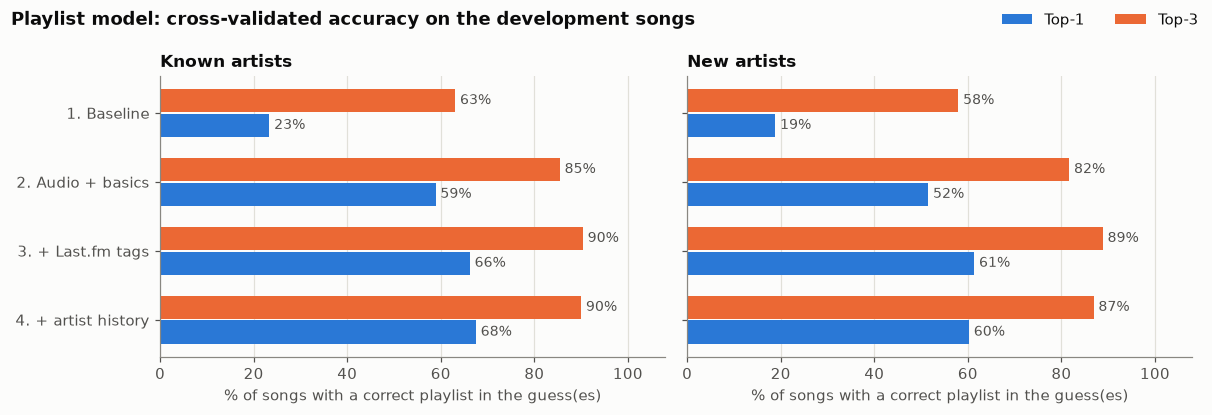

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y_pos = np.arange(len(VERSIONS))[::-1]
for ax, scen in zip(axes, ["known artists", "new artists"]):
    t1, t3 = cv[(scen, "top-1")].values * 100, cv[(scen, "top-3")].values * 100
    ax.barh(y_pos + 0.18, t3, height=0.34, color=COLORS[1], label="Top-3")
    ax.barh(y_pos - 0.18, t1, height=0.34, color=COLORS[0], label="Top-1")
    for y_, a, b in zip(y_pos, t1, t3):
        ax.text(a + 1, y_ - 0.18, f"{a:.0f}%", va="center", color=TEXT_2, fontsize=9)
        ax.text(b + 1, y_ + 0.18, f"{b:.0f}%", va="center", color=TEXT_2, fontsize=9)
    ax.set_xlim(0, 108)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{scen.capitalize()}", fontsize=11)
    ax.set_xlabel("% of songs with a correct playlist in the guess(es)")
axes[0].set_yticks(y_pos, list(VERSIONS))
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="upper right", ncol=2)
fig.suptitle("Playlist model: cross-validated accuracy on the development songs", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "playlist_model_versions.png")
plt.show()

### Picking the final version

The rule, set before looking at the final test set: **the version with the best new-artist top-1 in cross-validation**, since the final test set is made of new artists. If two versions are within 1 point, the simpler one wins.

In [9]:
new_top1 = cv[("new artists", "top-1")]
best = new_top1.max()
CHOSEN = [v for v in VERSIONS if new_top1[v] >= best - 0.01][0]  # VERSIONS is ordered simplest first
print(f"Chosen: {CHOSEN} (new-artist CV top-1 {new_top1[CHOSEN]:.1%})")

Chosen: 3. + Last.fm tags (new-artist CV top-1 61.4%)


### Which playlists are easy, and which get mixed up?

**Average precision** per label measures how well the model ranks that label's songs above the rest (from the cross-validation predictions of the chosen version). It's compared with the label's share of songs, which is what random guessing would score.

In [10]:
per_label = pd.DataFrame({"songs": Y_dev.sum(), "random guessing": Y_dev.mean()})
for scen in SCENARIOS:
    p = oof[(scen, CHOSEN)]
    per_label[scen] = [average_precision_score(Y_dev[c], p[:, i]) for i, c in enumerate(LABEL_ORDER)]
print(per_label.round(2).sort_values("known artists", ascending=False).to_string())

             songs  random guessing  known artists  new artists
label                                                          
Country        520             0.24           0.96         0.94
Hip Hop/Rap    168             0.08           0.65         0.59
Sad Vibes      500             0.23           0.58         0.54
Hype           332             0.15           0.55         0.53
Fall           524             0.24           0.51         0.41
Cute           384             0.18           0.48         0.36
Boat Songs     199             0.09           0.48         0.46
Sunset         443             0.21           0.46         0.43


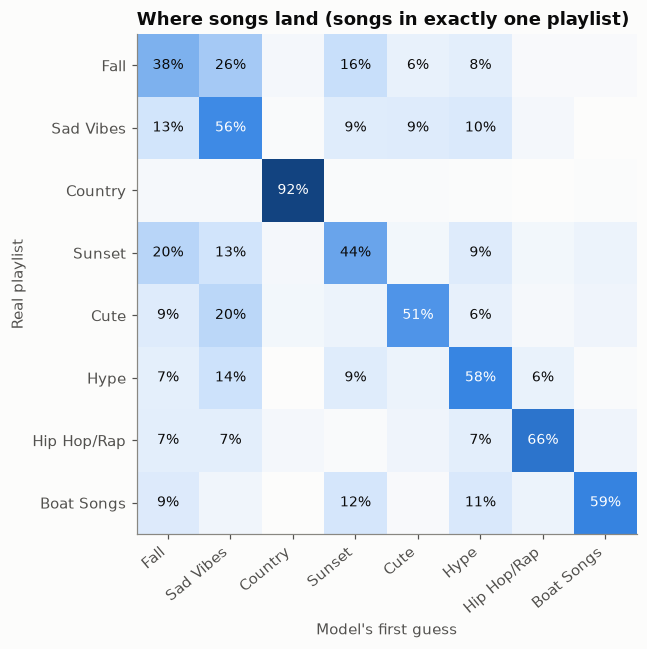

Most common mix-ups (real -> guessed):
row_0   col_0    
Fall    Sad Vibes    26%
Sunset  Fall         20%
Cute    Sad Vibes    20%
Fall    Sunset       16%
Hype    Sad Vibes    14%
Sunset  Sad Vibes    13%


In [11]:
# For songs with exactly one label: where does the model's first guess go? (known-artist scenario)
probs = oof[("known artists", CHOSEN)]
single = (Y_dev.sum(axis=1) == 1).values
true_label = Y_dev[single].idxmax(axis=1)
guess = pd.Series(np.array(LABEL_ORDER)[probs[single].argmax(axis=1)], index=true_label.index)
confusion = (pd.crosstab(true_label, guess, normalize="index")
             .reindex(index=LABEL_ORDER, columns=LABEL_ORDER).fillna(0))

fig, ax = plt.subplots(figsize=(7.5, 6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", BLUES)
ax.imshow(confusion.values, cmap=cmap, vmin=0, vmax=1)
ax.grid(False)
for i in range(len(LABEL_ORDER)):
    for j in range(len(LABEL_ORDER)):
        v = confusion.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.5 else TEXT)
ax.set_xticks(range(len(LABEL_ORDER)), LABEL_ORDER, rotation=40, ha="right")
ax.set_yticks(range(len(LABEL_ORDER)), LABEL_ORDER)
ax.set_xlabel("Model's first guess")
ax.set_ylabel("Real playlist")
ax.set_title("Where songs land (songs in exactly one playlist)")
fig.tight_layout()
fig.savefig(FIG / "playlist_confusion.png")
plt.show()

off = confusion.where(~np.eye(len(LABEL_ORDER), dtype=bool)).stack().sort_values(ascending=False).head(6)
print("Most common mix-ups (real -> guessed):")
print((off * 100).round(0).astype(int).astype(str).add("%").to_string())

## 6. Final test (run once)

The chosen version is trained on all development songs and scored on the locked-away test set. Every artist in the test set is new to the model, so this is comparable to the "new artists" cross-validation column.

In [12]:
final_dev = VERSIONS[CHOSEN]().fit(X_dev, Y_dev)
test_probs = final_dev.predict_proba(X_test)
base_probs = VERSIONS["1. Baseline"]().fit(X_dev, Y_dev).predict_proba(X_test)

t1, t3 = top_k(Y_test, test_probs)
b1, b3 = top_k(Y_test, base_probs)
print(f"Final test set ({len(X_test)} songs, all by new artists)")
print(f"  {CHOSEN}: top-1 {t1:.1%}, top-3 {t3:.1%}")
print(f"  Baseline:      top-1 {b1:.1%}, top-3 {b3:.1%}")
print(f"  New-artist CV for comparison: top-1 {cv.loc[CHOSEN, ('new artists', 'top-1')]:.1%}, "
      f"top-3 {cv.loc[CHOSEN, ('new artists', 'top-3')]:.1%}")

Final test set (311 songs, all by new artists)
  3. + Last.fm tags: top-1 54.7%, top-3 83.9%
  Baseline:      top-1 21.2%, top-3 54.3%
  New-artist CV for comparison: top-1 61.4%, top-3 88.9%


## 7. Playlist suggestions for songs I never sorted

After the final test, the chosen version is retrained on **all** labeled songs (development + test), since more data makes better suggestions. It then scores every Liked Song that isn't in any of the 8 vibe playlists, including other versions of songs that are (matched by song key). Each song gets its best-fitting playlist, how confident the model is (0 to 1), and a runner-up.

Confidence is the model's probability for that playlist. Each label is scored separately, so the numbers don't add up to 1 across playlists, and a song can be a strong fit for two. These are suggestions to check, not answers.

In [13]:
final = VERSIONS[CHOSEN]().fit(X, Y)

liked_clean = pd.read_csv("liked_songs_clean.csv")
liked_clean["key"] = [song_key(t, a) for t, a in zip(liked_clean["track"], liked_clean["artist"])]
cand = liked_clean[~liked_clean["key"].isin(Y.index) & liked_clean["track_id"].isin(feat.index)]
cand = cand.drop_duplicates("key")
p = pd.DataFrame(final.predict_proba(feat.loc[cand["track_id"]]), index=cand["track_id"], columns=LABEL_ORDER)

order = np.argsort(-p.values, axis=1)
sugg = cand.set_index("track_id")[["track", "artist"]].copy()
sugg["suggested_playlist"] = np.array(LABEL_ORDER)[order[:, 0]]
sugg["confidence"] = p.values[np.arange(len(p)), order[:, 0]].round(3)
sugg["runner_up"] = np.array(LABEL_ORDER)[order[:, 1]]
sugg["runner_up_confidence"] = p.values[np.arange(len(p)), order[:, 1]].round(3)
sugg = sugg.sort_values(["suggested_playlist", "confidence"], ascending=[True, False])
sugg.reset_index().to_csv("playlist_suggestions.csv", index=False)

print(f"Saved playlist_suggestions.csv: {len(sugg)} Liked Songs not in any vibe playlist\n")
print(sugg["suggested_playlist"].value_counts().to_string())
print(f"\nConfident suggestions (0.5 or higher): {(sugg['confidence'] >= 0.5).sum()}")

Saved playlist_suggestions.csv: 2501 Liked Songs not in any vibe playlist

suggested_playlist
Sad Vibes      570
Sunset         419
Hype           408
Hip Hop/Rap    312
Cute           309
Fall           280
Boat Songs     118
Country         85

Confident suggestions (0.5 or higher): 1286


In [14]:
pd.set_option("display.width", 200, "display.max_colwidth", 40)
for label in LABEL_ORDER:
    top = sugg[sugg["suggested_playlist"] == label].nlargest(6, "confidence")
    print(f"--- {label} ---")
    print(top[["track", "artist", "confidence"]].to_string(index=False, header=False) if len(top) else "  (none)")

--- Fall ---
             Believe      Caamp 0.951
    Apple Tree Blues      Caamp 0.949
Going to the Country      Caamp 0.930
  Send the Fisherman      Caamp 0.906
     My Stupid Mouth John Mayer 0.902
             So Cool      Caamp 0.897
--- Sad Vibes ---
                   epiphany   Taylor Swift 0.958
                 the grudge Olivia Rodrigo 0.950
                 Hallelujah     Pentatonix 0.946
                       Risk  Gracie Abrams 0.942
Cayendo (Side A - Acoustic)    Frank Ocean 0.935
    The Day Before You Came   Meryl Streep 0.926
--- Country ---
                      Emerald City     Kelsea Ballerini 0.999
         Where the Wild Things Are           Luke Combs 0.999
I Only Miss You (feat. Ed Sheeran)        Megan Moroney 0.999
         Sleepless in a Hotel Room           Luke Combs 0.999
                Let Your Love Flow The Bellamy Brothers 0.999
                   Ain’t That Some        Morgan Wallen 0.999
--- Sunset ---
         Monday Morning    Quinn XCII 0.959


## 8. A version for predicting any song

`predict_playlist.py` can score any song on Spotify, not just my Liked Songs. The tested model has two features that describe *me* rather than the song: whether the song is in my Liked Songs, and my Last.fm play count. A song I've never heard always looks like "not liked, 0 plays", which was rare in training and mostly showed up in Hype and Sad Vibes (older playlists with songs I never liked). So the model could push every new song toward those playlists no matter how it sounds.

The predictor therefore uses the same design as the tested model **without those two features**.

This version is checked **only with cross-validation on the development songs**, in both scenarios. It is *not* scored on the final test set: I decided to make this change after already seeing the test result, so a second test score wouldn't be an honest, untouched estimate. The official results above stay the official results.

In [15]:
# Same design as the chosen version, minus the two personal features
use_tags = CHOSEN != "2. Audio + basics"
use_artist = CHOSEN == "4. + artist history"
predictor_version = lambda: make_version(use_tags=use_tags, use_artist=use_artist, basic=SONG_ONLY)

rows = []
for scen, splitter in SCENARIOS.items():
    groups = groups_dev if isinstance(splitter, GroupKFold) else None
    probs = np.zeros(Y_dev.shape)
    for tr, te in splitter.split(X_dev, groups=groups):
        probs[te] = predictor_version().fit(X_dev.iloc[tr], Y_dev.iloc[tr]).predict_proba(X_dev.iloc[te])
    top1, top3 = top_k(Y_dev, probs)
    rows.append({"scenario": scen, "tested model: top-1": cv.loc[CHOSEN, (scen, "top-1")],
                 "predictor: top-1": top1, "tested model: top-3": cv.loc[CHOSEN, (scen, "top-3")],
                 "predictor: top-3": top3})
print("Cross-validation on the development songs (%):")
print((pd.DataFrame(rows).set_index("scenario") * 100).round(1).to_string())

Cross-validation on the development songs (%):
               tested model: top-1  predictor: top-1  tested model: top-3  predictor: top-3
scenario                                                                                   
known artists                 66.2              64.1                 90.4              88.9
new artists                   61.4              60.6                 88.9              87.0


In [16]:
# Train the predictor on all labeled songs and save it for predict_playlist.py
predictor = predictor_version().fit(X, Y)
Path("models").mkdir(exist_ok=True)
joblib.dump({"model": predictor, "labels": LABEL_ORDER, "trained_on_songs": len(Y)}, "models/playlist_model.joblib")
print(f"Saved models/playlist_model.joblib ({Path('models/playlist_model.joblib').stat().st_size / 1e6:.1f} MB)")

# How often does it agree with the tested model on my unsorted Liked Songs?
p_pred = predictor.predict_proba(feat.loc[cand["track_id"]])
same_top = (p_pred.argmax(axis=1) == p.values.argmax(axis=1)).mean()
print(f"Same top suggestion as the tested model for {same_top:.0%} of the {len(cand)} unsorted Liked Songs")

Saved models/playlist_model.joblib (4.6 MB)


Same top suggestion as the tested model for 80% of the 2501 unsorted Liked Songs


## 9. My monthly playlists, April 2019 to August 2020

From April 2019 to August 2020 I made a playlist for (almost) every month. They're a snapshot of what I was into at each point, so here's how they shifted. Lines are medians across each playlist's songs with audio features.

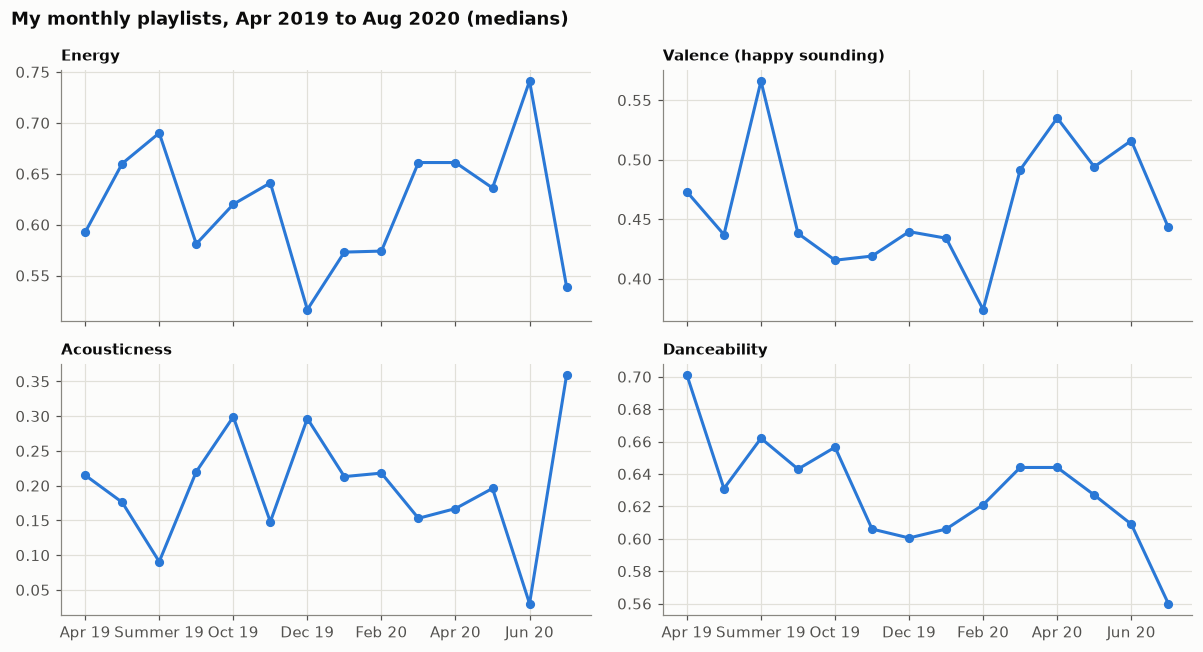

           songs  energy  valence  acousticness  pct_hiphop  pct_country  pct_explicit
month                                                                                 
Apr 19        65    0.59     0.47          0.22       12.31        10.77         16.92
May 19       124    0.66     0.44          0.18       22.58         3.23         24.19
Summer 19    329    0.69     0.57          0.09       22.49         9.12         20.06
Sep 19       387    0.58     0.44          0.22       22.74        13.18         23.26
Oct 19       123    0.62     0.42          0.30       23.58         3.25         31.71
Nov 19       216    0.64     0.42          0.15       21.30        11.57         23.61
Dec 19       104    0.52     0.44          0.30       12.50         4.81         17.31
Jan 20       306    0.57     0.43          0.21       37.25         3.59         36.93
Feb 20        71    0.57     0.37          0.22       18.31         4.23         23.94
Mar 20       131    0.66     0.49          

In [17]:
MONTHLY = {"April19": "Apr 19", "May19": "May 19", "Summer19": "Summer 19", "September19": "Sep 19",
           "October19": "Oct 19", "Turkey Time- November": "Nov 19", "December19": "Dec 19", "Jan2020": "Jan 20",
           "Feb20": "Feb 20", "March20": "Mar 20", "April20": "Apr 20", "May20": "May 20", "June20": "Jun 20",
           "august 20": "Aug 20"}
monthly = (pl.loc[pl["playlist"].isin(MONTHLY), ["playlist", "track_id"]]
           .drop_duplicates().join(feat, on="track_id"))
monthly["month"] = pd.Categorical(monthly["playlist"].map(MONTHLY), categories=list(MONTHLY.values()), ordered=True)
tag_list = monthly["tags"].str.split("|")
monthly["hip-hop/rap tag"] = tag_list.map(lambda ts: any("hip-hop" in t or "rap" in t for t in ts))
monthly["country tag"] = tag_list.map(lambda ts: any("country" in t for t in ts))

TRENDS = {"energy": "Energy", "valence": "Valence (happy sounding)", "acousticness": "Acousticness",
          "danceability": "Danceability"}
g = monthly.groupby("month", observed=True)
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
x = np.arange(len(MONTHLY))
for ax, (col, title) in zip(axes.flat, TRENDS.items()):
    ax.plot(x, g[col].median().values, color=COLORS[0], linewidth=2, marker="o", markersize=5)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(x[::2], list(MONTHLY.values())[::2])
fig.suptitle("My monthly playlists, Apr 2019 to Aug 2020 (medians)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "monthly_playlists.png")
plt.show()

table = g.agg(songs=("track_id", "size"), energy=("energy", "median"), valence=("valence", "median"),
              acousticness=("acousticness", "median"), pct_hiphop=("hip-hop/rap tag", "mean"),
              pct_country=("country tag", "mean"), pct_explicit=("explicit", "mean"))
table[["pct_hiphop", "pct_country", "pct_explicit"]] *= 100
print(table.round(2).to_string())